In [2]:
import os, re, glob, math, shutil, zipfile
from pathlib import Path
import numpy as np, pandas as pd, cv2
import matplotlib.pyplot as plt
from tqdm.auto import tqdm

from google.colab import drive
drive.mount('/content/drive')

ZIP     = "/content/drive/MyDrive/hasil_citra_15_zip.zip"
IN_DIR  = "/content/input"
OUT_DIR = "/content/hasil_fitur"
os.makedirs(IN_DIR, exist_ok=True)
os.makedirs(OUT_DIR, exist_ok=True)

with zipfile.ZipFile(ZIP) as z:
    print(len(z.namelist()), "files")
    z.extractall(IN_DIR)

paths = sorted(p for p in glob.glob(f"{IN_DIR}/**/*", recursive=True)
               if p.lower().endswith((".jpg", ".jpeg", ".png")))
print("Images:", len(paths))

# Struktur: <jenis buah> fruit / Image_N / <varian>.png
# Urutan varian dibuat dari awalan nama, jadi aman untuk median15 / median31 / dst.
VARIAN_PREFIX = ["1_grayscale", "2_CS", "2_HE", "2_CLAHE",
                 "3_CS_median", "3_HE_median", "3_CLAHE_median"]

def urut_varian(v):
    v = str(v)
    for i, pre in enumerate(VARIAN_PREFIX):
        if v == pre or (pre.endswith("median") and v.startswith(pre)):
            return (i, v)
    return (99, v)

def parse_path(p):
    pp = Path(p)
    return dict(Buah=pp.parent.parent.name.replace(" fruit", ""),   # apple, banana, ...
                Sampel=pp.parent.name,                               # Image_1, Image_2, ...
                Varian=pp.stem)                                      # 1_grayscale, 3_CLAHE_median15, ...

# Cek parsing: harus muncul 9 buah dan 7 varian
meta = pd.DataFrame([parse_path(p) for p in paths])
print("\nJumlah citra per buah:");   print(meta.Buah.value_counts().sort_index().to_string())
print("\nJumlah citra per varian:"); print(meta.Varian.value_counts().sort_index().to_string())

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
2881 files
Images: 2513

Jumlah citra per buah:
Buah
apple         280
banana        280
cherry        280
chickoo       280
grapes        280
kiwi          280
mango         273
orange        280
strawberry    280

Jumlah citra per varian:
Varian
1_grayscale         359
2_CLAHE             359
2_CS                359
2_HE                359
3_CLAHE_median15    359
3_CS_median15       359
3_HE_median15       359


In [3]:
# ==== Fitur tekstur: Gabor filter bank (pengganti GLCM) ====
GABOR_THETAS      = [0, 45, 90, 135]   # orientasi (derajat). 0 = garis vertikal, 90 = garis horizontal
GABOR_LAMBDAS     = [4, 8]             # panjang gelombang (piksel, pada citra 128x128): halus & kasar
GABOR_SIGMA_RATIO = 0.56               # sigma = 0.56 * lambda
GABOR_GAMMA       = 0.5                # aspek elips envelope

def _bangun_bank():
    """Pasangan kernel kuadratur (cos & sin) untuk setiap kombinasi orientasi x panjang gelombang."""
    bank = []
    for th in GABOR_THETAS:
        for lam in GABOR_LAMBDAS:
            sigma = GABOR_SIGMA_RATIO * lam
            ks = int(6 * sigma) | 1                      # ukuran kernel ganjil
            pair = []
            for psi in (0, np.pi / 2):
                k = cv2.getGaborKernel((ks, ks), sigma, np.deg2rad(th), lam,
                                       GABOR_GAMMA, psi, ktype=cv2.CV_32F)
                k = k - k.mean()                         # buang komponen DC (tidak peka kecerahan rata-rata)
                k = k / (np.abs(k).sum() + 1e-9)         # normalisasi skala
                pair.append(k)
            bank.append((th, lam, pair[0], pair[1]))
    return bank

GABOR_BANK = _bangun_bank()
print("Jumlah filter Gabor:", len(GABOR_BANK), "(", len(GABOR_THETAS), "orientasi x", len(GABOR_LAMBDAS), "panjang gelombang )")

# Konvolusi lewat FFT: spektrum kernel dihitung sekali (cache), jauh lebih cepat daripada
# cv2.filter2D untuk kernel besar. Tepi citra diberi padding refleksi agar tidak terbungkus.
_FFT_PAD = max(k.shape[0] for _, _, k, _ in GABOR_BANK) // 2 + 1
_KF_CACHE = {}

def _spektrum_kernel(N):
    if N not in _KF_CACHE:
        spec = []
        for th, lam, kr, ki in GABOR_BANK:
            pair = []
            for k in (kr, ki):
                h = k.shape[0]
                pad = np.zeros((N, N), np.float32)
                pad[:h, :h] = k
                pad = np.roll(pad, (-(h // 2), -(h // 2)), axis=(0, 1))   # pusat kernel di (0,0)
                pair.append(np.fft.rfft2(pad))
            spec.append(tuple(pair))
        _KF_CACHE[N] = spec
    return _KF_CACHE[N]

def _gabor_respons(gray):
    """Magnitudo respons tiap filter: sqrt(real^2 + imajiner^2). Citra tetap skala 0-255."""
    g = gray.astype(np.float32)
    H, W = g.shape
    P = _FFT_PAD
    N = cv2.getOptimalDFTSize(max(H, W) + 2 * P)
    gp = np.zeros((N, N), np.float32)
    gp[:H + 2 * P, :W + 2 * P] = cv2.copyMakeBorder(g, P, P, P, P, cv2.BORDER_REFLECT_101)
    F = np.fft.rfft2(gp)
    out = []
    for (th, lam, _, _), (Kr, Ki) in zip(GABOR_BANK, _spektrum_kernel(N)):
        re = np.fft.irfft2(F * Kr, s=(N, N))[P:P + H, P:P + W]
        im = np.fft.irfft2(F * Ki, s=(N, N))[P:P + H, P:P + W]
        out.append((th, lam, np.sqrt(re * re + im * im).astype(np.float32)))
    return out

def _gabor_peta(gray):
    """Peta respons rata-rata semua filter (untuk visualisasi)."""
    return np.mean([m for _, _, m in _gabor_respons(gray)], axis=0)

def _gabor_features(gray):
    """8 fitur Gabor: mean, std, energy, anisotropi, dan energi per orientasi."""
    resp = _gabor_respons(gray)
    mean_f = [m.mean() for _, _, m in resp]
    std_f  = [m.std() for _, _, m in resp]
    en_f   = [(m ** 2).mean() for _, _, m in resp]

    e_theta = {th: float(np.mean([e for (t, _, _), e in zip(resp, en_f) if t == th]))
               for th in GABOR_THETAS}
    ev = np.array(list(e_theta.values()))

    out = {'gabor_mean':   float(np.mean(mean_f)),
           'gabor_std':    float(np.mean(std_f)),
           'gabor_energy': float(np.mean(en_f)),
           'gabor_aniso':  float(ev.std() / (ev.mean() + 1e-12))}   # 0 = merata ke semua arah
    for th in GABOR_THETAS:
        out[f'gabor_e{th}'] = e_theta[th]
    return out

    # ==== Fitur bentuk (Otsu + morfologi), dari repo fruit-recognition ====
def _segmentasi(gray):
    """Otsu -> pastikan buah putih -> opening & closing (morfologi)."""
    _, m = cv2.threshold(gray, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
    tepi = np.concatenate([m[0], m[-1], m[:, 0], m[:, -1]])
    if tepi.mean() > 127:                 # tepi putih = latar putih -> balik
        m = cv2.bitwise_not(m)
    k = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (5, 5))
    return cv2.morphologyEx(cv2.morphologyEx(m, cv2.MORPH_OPEN, k), cv2.MORPH_CLOSE, k)

def _shape_features(gray):
    m = _segmentasi(gray)
    cnts, _ = cv2.findContours(m, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    if not cnts:
        return dict(area=0, circularity=0, aspect_ratio=0, solidity=0, extent=0), m
    c = max(cnts, key=cv2.contourArea)
    area, per = cv2.contourArea(c), cv2.arcLength(c, True)
    x, y, w, h = cv2.boundingRect(c)
    hull = cv2.contourArea(cv2.convexHull(c))
    return dict(area=area / m.size,
                circularity=4 * math.pi * area / (per ** 2 + 1e-9),
                aspect_ratio=w / (h + 1e-9),
                solidity=area / (hull + 1e-9),
                extent=area / (w * h + 1e-9)), m

Jumlah filter Gabor: 8 ( 4 orientasi x 2 panjang gelombang )


In [4]:
# ==== Gabungan fitur + tafsir ====
def extract_features(gray):
    gray = cv2.resize(gray, (128, 128))
    gab = _gabor_features(gray)
    shape, mask = _shape_features(gray)
    return {**gab, **shape, '_gray': gray, '_mask': mask}

TEKSTUR_COLS = ['gabor_mean', 'gabor_std', 'gabor_energy', 'gabor_aniso'] + [f'gabor_e{t}' for t in GABOR_THETAS]
BENTUK_COLS  = ['area', 'circularity', 'aspect_ratio', 'solidity', 'extent']
FEATURE_COLS = TEKSTUR_COLS + BENTUK_COLS

ORIENT_LABEL = {0: "garis vertikal (0°)", 45: "diagonal 45°",
                90: "garis horizontal (90°)", 135: "diagonal 135°"}

def tafsir_tekstur(f, ref):
    """Relatif terhadap dataset (tertil bawah/tengah/atas) pada varian yang sama,
    karena skala respons Gabor bergantung pada citra (mis. median besar membuatnya kecil semua)."""
    kunci = ['gabor_energy', 'gabor_std', 'gabor_aniso']
    q = ref[kunci].quantile([1/3, 2/3])
    def lvl(k, rendah, sedang, tinggi):
        v = f[k]
        return rendah if v <= q[k].iloc[0] else tinggi if v >= q[k].iloc[1] else sedang
    e = {t: float(f[f'gabor_e{t}']) for t in GABOR_THETAS}
    dom = max(e, key=e.get)
    return "; ".join([
        lvl('gabor_energy', "tekstur halus/datar",        "tekstur sedang",               "tekstur kuat/berdetail"),
        lvl('gabor_std',    "respons merata",             "respons cukup bervariasi",     "respons sangat bervariasi (pola/bintik lokal)"),
        lvl('gabor_aniso',  "arah tekstur merata",        "arah tekstur agak condong",    "satu arah tekstur dominan"),
        f"arah terkuat: {ORIENT_LABEL[dom]}"])

def tafsir_bentuk(f):
    ar, ci, so, ex = f['aspect_ratio'], f['circularity'], f['solidity'], f['extent']
    return "; ".join([
        "memanjang horizontal" if ar > 1.25 else "memanjang vertikal" if ar < 0.75 else "proporsi hampir sama",
        "kontur mendekati lingkaran" if ci > 0.6 else "kontur agak bulat" if ci > 0.4 else "kontur tidak bulat/tidak rata",
        "bentuk cembung/utuh" if so > 0.9 else "ada lekukan" if so > 0.75 else "banyak lekukan/tonjolan",
        "mengisi hampir seluruh kotak pembatas" if ex > 0.7 else "mengisi sebagian kotak pembatas"])

## Ekstraksi semua citra

  0%|          | 0/2513 [00:00<?, ?it/s]

df dibuat: 2513 baris | Gagal dibaca: 0
Varian di data: ['1_grayscale', '2_CS', '2_HE', '2_CLAHE', '3_CS_median15', '3_HE_median15', '3_CLAHE_median15']
Dibandingkan: 1_grayscale vs 3_CLAHE_median15


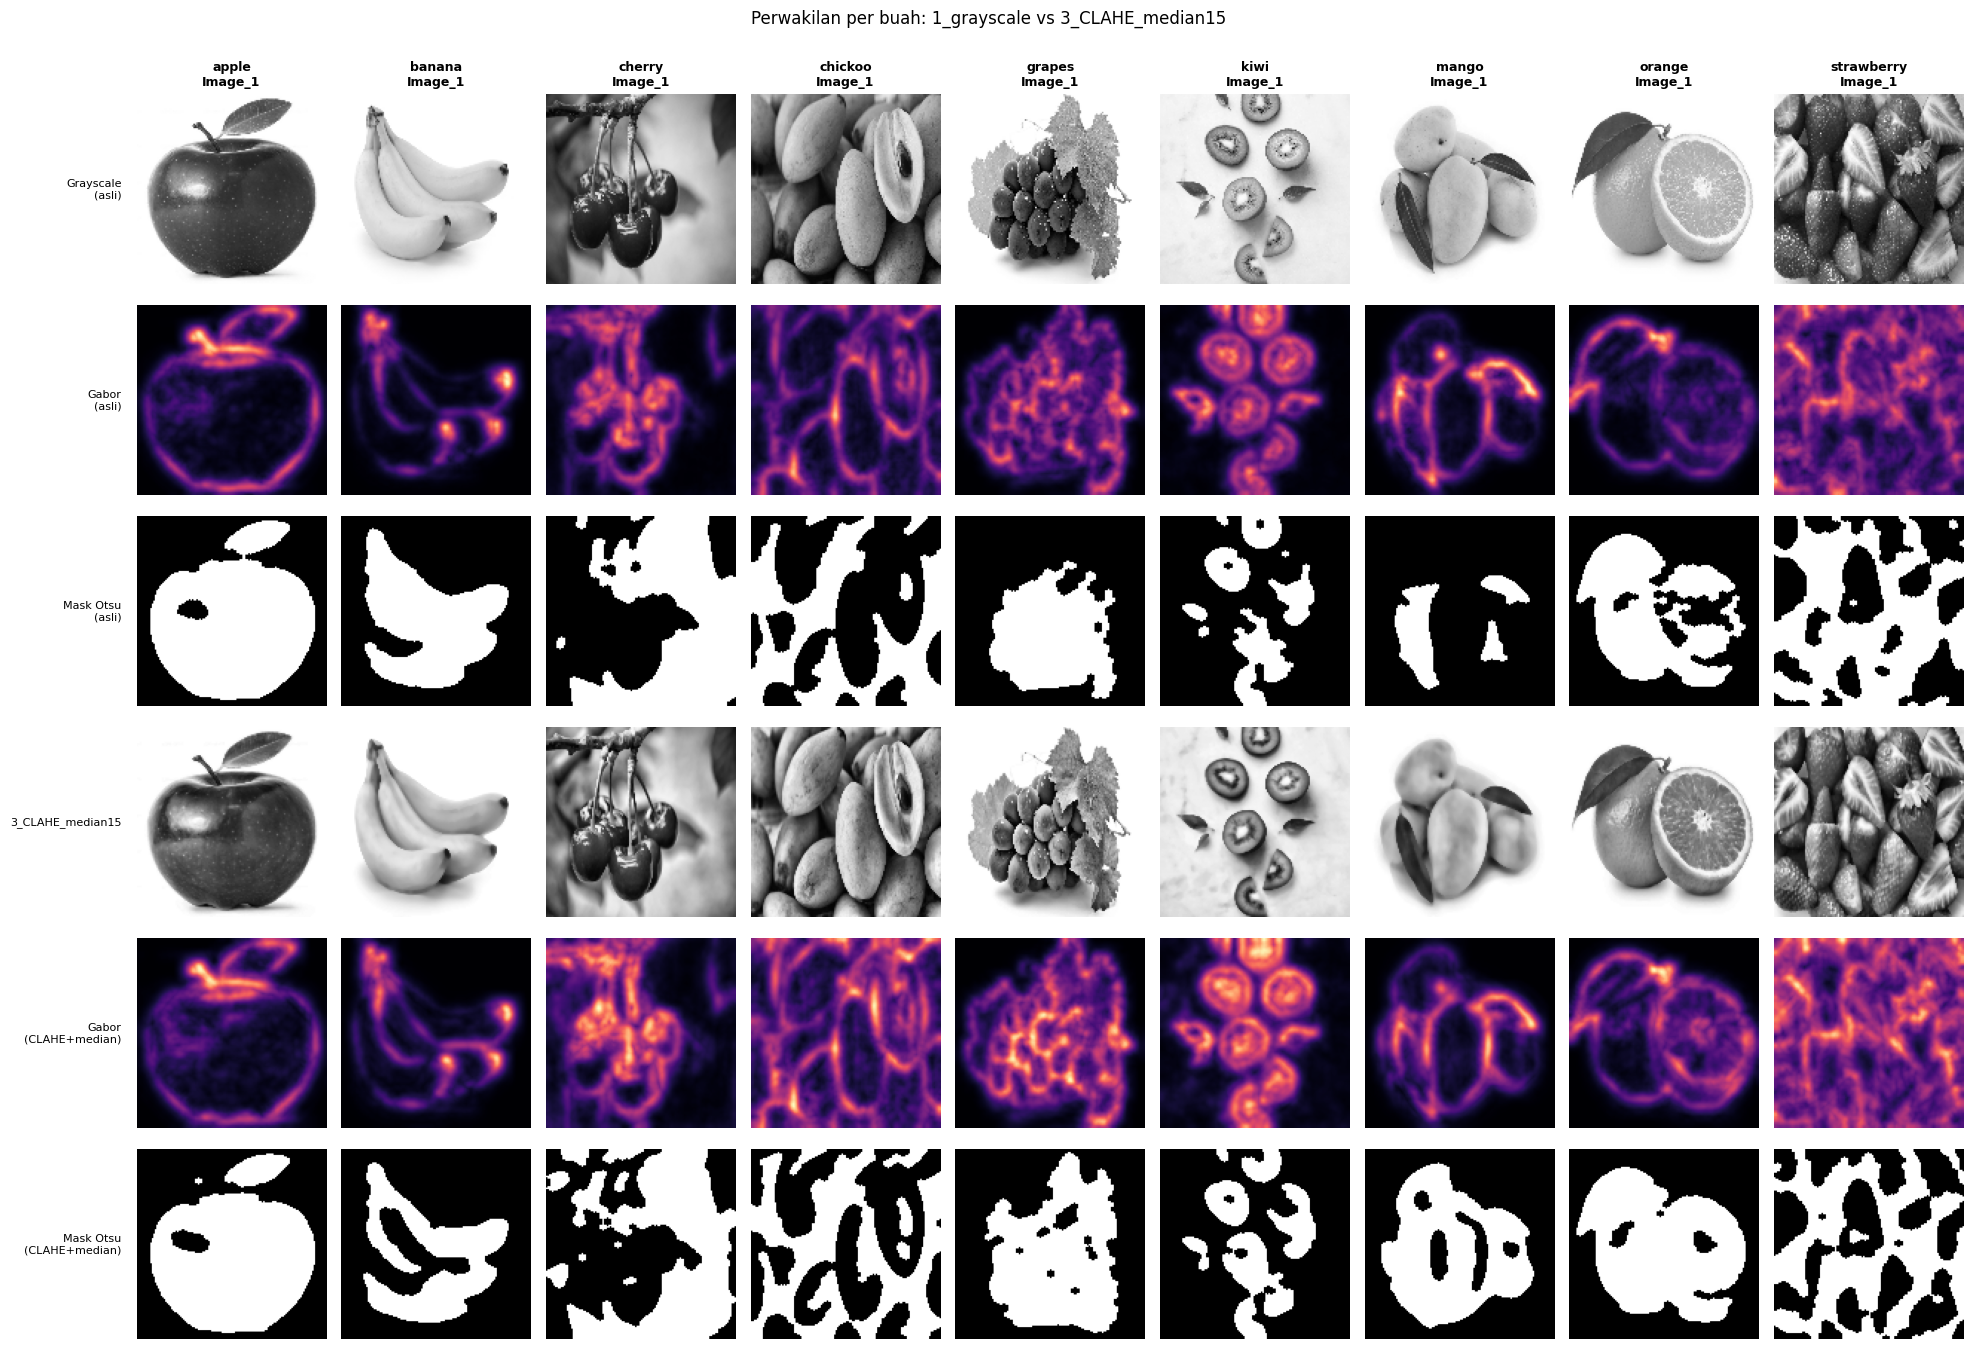

=== 1_grayscale ===


,gabor_mean,gabor_std,gabor_energy,gabor_aniso,gabor_e0,gabor_e45,gabor_e90,gabor_e135,area,circularity,aspect_ratio,solidity,extent
Buah,,,,,,,,,,,,,
apple,2.2275,4.1459,25.0074,0.6470,10.6844,19.7230,52.4440,17.1783,0.5430,0.5117,0.9174,0.8957,0.6624
banana,1.1429,2.2346,6.8642,0.4665,11.9143,3.0643,5.8606,6.6175,0.3339,0.3275,0.8981,0.7355,0.5221
cherry,3.0161,3.9898,27.6982,0.6286,57.6922,17.9055,20.1468,15.0484,0.4716,0.2180,0.8750,0.6231,0.5389
chickoo,3.2125,3.5458,27.8085,0.8767,69.6452,16.0694,8.4875,17.0320,0.2385,0.1874,0.6484,0.5717,0.3678
grapes,3.1293,3.4200,22.4683,0.4290,39.0175,15.1137,18.7022,17.0398,0.3109,0.3140,0.9247,0.8079,0.6369
kiwi,2.8164,3.7983,23.1446,0.1506,27.0120,19.0832,26.1686,20.3146,0.0729,0.1898,0.6212,0.6389,0.4416
mango,1.5864,2.9133,11.9553,0.4659,19.8793,5.2553,8.5447,14.1419,0.0766,0.3967,0.4167,0.7570,0.5812
orange,1.8045,2.8410,11.5484,0.1765,10.7376,13.7845,13.0653,8.6061,0.3946,0.1461,1.1068,0.7538,0.5506
strawberry,4.2548,3.4610,31.5950,0.4158,54.1225,23.3897,21.8951,26.9725,0.6516,0.1595,1.0000,0.7206,0.6516


=== 3_CLAHE_median15 ===


,gabor_mean,gabor_std,gabor_energy,gabor_aniso,gabor_e0,gabor_e45,gabor_e90,gabor_e135,area,circularity,aspect_ratio,solidity,extent
Buah,,,,,,,,,,,,,
apple,2.3787,3.9637,25.0990,0.7160,9.7945,18.8541,55.7044,16.0431,0.5020,0.8362,1.1684,0.9807,0.7799
banana,1.3927,2.5845,9.6969,0.4646,16.5612,3.9781,8.5226,9.7258,0.2548,0.1244,0.9074,0.5537,0.3944
cherry,3.9894,4.8866,44.9775,0.6826,97.8879,27.1397,31.7549,23.1273,0.4276,0.1364,0.8906,0.5448,0.4801
chickoo,4.5098,4.6268,50.3123,0.8374,122.3459,35.1475,16.2024,27.5535,0.5391,0.1165,1.0000,0.5692,0.5391
grapes,3.9490,4.3970,37.0161,0.4922,68.4833,24.7804,26.1736,28.6270,0.4435,0.3708,0.7377,0.8303,0.6618
kiwi,3.7071,4.7655,38.6310,0.1634,48.6726,32.7238,39.3199,33.8078,0.0961,0.2055,0.6667,0.6758,0.4554
mango,1.6740,2.9667,13.4909,0.6108,27.1876,6.8363,7.2406,12.6989,0.4386,0.6465,0.9196,0.8998,0.6230
orange,2.4981,3.6724,20.0553,0.0914,21.8532,21.2312,20.0512,17.0857,0.4784,0.4551,1.0857,0.8992,0.6548
strawberry,5.3569,4.2038,49.7172,0.4521,87.1460,40.3716,27.3704,43.9808,0.6137,0.0943,1.0000,0.6557,0.6137


=== Selisih (3_CLAHE_median15 - 1_grayscale) ===


,gabor_mean,gabor_std,gabor_energy,gabor_aniso,gabor_e0,gabor_e45,gabor_e90,gabor_e135,area,circularity,aspect_ratio,solidity,extent
Buah,,,,,,,,,,,,,
apple,0.1512,-0.1822,0.0916,0.0690,-0.8899,-0.8689,3.2604,-1.1352,-0.0410,0.3245,0.2510,0.0850,0.1175
banana,0.2498,0.3499,2.8327,-0.0019,4.6469,0.9138,2.6620,3.1083,-0.0791,-0.2031,0.0093,-0.1818,-0.1277
cherry,0.9733,0.8968,17.2793,0.0540,40.1957,9.2342,11.6081,8.0789,-0.0440,-0.0816,0.0156,-0.0783,-0.0588
chickoo,1.2973,1.0810,22.5038,-0.0393,52.7007,19.0781,7.7149,10.5215,0.3006,-0.0709,0.3516,-0.0025,0.1713
grapes,0.8197,0.9770,14.5478,0.0632,29.4658,9.6667,7.4714,11.5872,0.1326,0.0568,-0.1870,0.0224,0.0249
kiwi,0.8907,0.9672,15.4864,0.0128,21.6606,13.6406,13.1513,13.4932,0.0232,0.0157,0.0455,0.0369,0.0138
mango,0.0876,0.0534,1.5356,0.1449,7.3083,1.5810,-1.3041,-1.4430,0.3620,0.2498,0.5029,0.1428,0.0418
orange,0.6936,0.8314,8.5069,-0.0851,11.1156,7.4467,6.9859,8.4796,0.0838,0.3090,-0.0211,0.1454,0.1042
strawberry,1.1021,0.7428,18.1222,0.0363,33.0235,16.9819,5.4753,17.0083,-0.0379,-0.0652,0.0000,-0.0649,-0.0379



=== Ringkasan per buah ===

[apple / Image_1]
  Perubahan: gabor_mean naik, gabor_std turun, gabor_energy naik, gabor_aniso naik, gabor_e0 turun, gabor_e45 turun, gabor_e90 naik, gabor_e135 turun, area turun, circularity naik, aspect_ratio naik, solidity naik, extent naik
  Asli           tekstur: tekstur sedang; respons sangat bervariasi (pola/bintik lokal); satu arah tekstur dominan; arah terkuat: garis horizontal (90°)
                 bentuk : proporsi hampir sama; kontur agak bulat; ada lekukan; mengisi sebagian kotak pembatas
  CLAHE+Median   tekstur: tekstur sedang; respons cukup bervariasi; satu arah tekstur dominan; arah terkuat: garis horizontal (90°)
                 bentuk : proporsi hampir sama; kontur mendekati lingkaran; bentuk cembung/utuh; mengisi hampir seluruh kotak pembatas

[banana / Image_1]
  Perubahan: gabor_mean naik, gabor_std naik, gabor_energy naik, gabor_aniso turun, gabor_e0 naik, gabor_e45 naik, gabor_e90 naik, gabor_e135 naik, area turun, circularity tu

In [6]:
# Perwakilan 1 sampel per buah: Grayscale vs CLAHE + Median
# ---- A. Ekstraksi fitur semua citra -> df ----
rows, gagal = [], []
for p in tqdm(paths):
    img = cv2.imread(p, cv2.IMREAD_GRAYSCALE)
    if img is None:
        gagal.append(p)
        continue
    f = extract_features(img)
    rows.append(dict(**parse_path(p), **{k: f[k] for k in FEATURE_COLS}))

df = pd.DataFrame(rows)
df["Sampel_No"] = df["Sampel"].str.extract(r"(\d+)").astype(float)
urut = sorted(df["Varian"].unique(), key=urut_varian)
df["Varian"] = pd.Categorical(df["Varian"], categories=urut, ordered=True)
df = df.sort_values(["Buah", "Sampel_No", "Varian"]).reset_index(drop=True)

# referensi tafsir: tekstur dibandingkan dengan citra yang varian-nya sama
ref = {v: g for v, g in df.groupby("Varian", observed=True)}
df["Tafsir_Tekstur"] = df.apply(lambda r: tafsir_tekstur(r, ref[r["Varian"]]), axis=1)
df["Tafsir_Bentuk"]  = df.apply(tafsir_bentuk, axis=1)
df.to_csv(f"{OUT_DIR}/fitur_semua_citra.csv", index=False)
print("df dibuat:", len(df), "baris | Gagal dibaca:", len(gagal))

# ---- B. Perwakilan 1 sampel per buah ----
print("Varian di data:", [str(v) for v in df["Varian"].unique()])
VAR_ASLI = "1_grayscale"
VAR_BARU = next((str(v) for v in df["Varian"].unique() if str(v).startswith("3_CLAHE_median")), None)
assert VAR_BARU, "Tidak ada varian '3_CLAHE_median*'. Lihat daftar varian di atas."
print("Dibandingkan:", VAR_ASLI, "vs", VAR_BARU)
REP_INDEX = 0          # 0 = sampel pertama tiap buah; ganti untuk memilih sampel lain

peta = {}
for p in paths:
    m = parse_path(p)
    peta[(m["Buah"], m["Sampel"], m["Varian"])] = p

def _no(s):
    x = re.search(r"\d+", s)
    return int(x.group()) if x else 0

buah_list = sorted(df["Buah"].unique())
perwakilan = {}
for b in buah_list:
    sampel_b = sorted({s for (bb, s, v) in peta
                       if bb == b and (b, s, VAR_ASLI) in peta and (b, s, VAR_BARU) in peta}, key=_no)
    if sampel_b:
        perwakilan[b] = sampel_b[REP_INDEX % len(sampel_b)]
buah_list = list(perwakilan)
n = len(buah_list)

# ---- gambar: 6 baris x n buah ----
fig, ax = plt.subplots(6, n, figsize=(2.2 * n, 13.5), squeeze=False)
for i, b in enumerate(buah_list):
    s = perwakilan[b]
    fa = extract_features(cv2.imread(peta[(b, s, VAR_ASLI)], cv2.IMREAD_GRAYSCALE))
    fb = extract_features(cv2.imread(peta[(b, s, VAR_BARU)], cv2.IMREAD_GRAYSCALE))
    ga, gb = _gabor_peta(fa['_gray']), _gabor_peta(fb['_gray'])
    vmax = max(ga.max(), gb.max(), 1e-6)            # skala sama agar bisa dibandingkan
    ax[0, i].imshow(fa['_gray'], cmap="gray", vmin=0, vmax=255)
    ax[0, i].set_title(f"{b}\n{s}", fontsize=9, fontweight="bold")
    ax[1, i].imshow(ga, cmap="magma", vmin=0, vmax=vmax)
    ax[2, i].imshow(fa['_mask'], cmap="gray")
    ax[3, i].imshow(fb['_gray'], cmap="gray", vmin=0, vmax=255)
    ax[4, i].imshow(gb, cmap="magma", vmin=0, vmax=vmax)
    ax[5, i].imshow(fb['_mask'], cmap="gray")
    for r in range(6): ax[r, i].axis("off")
for r, lbl in enumerate(["Grayscale\n(asli)", "Gabor\n(asli)", "Mask Otsu\n(asli)",
                         f"{VAR_BARU}", "Gabor\n(CLAHE+median)", "Mask Otsu\n(CLAHE+median)"]):
    ax[r, 0].text(-0.08, 0.5, lbl, transform=ax[r, 0].transAxes, ha="right", va="center", fontsize=8)
fig.suptitle(f"Perwakilan per buah: {VAR_ASLI} vs {VAR_BARU}", y=1.0)
plt.tight_layout(); plt.show()

# ---- tabel angka (diambil dari df, tidak dihitung ulang) ----
def baris(b, v):
    s = perwakilan[b]
    return df[(df["Buah"] == b) & (df["Sampel"] == s) & (df["Varian"] == v)].iloc[0]

def tabel(v):
    t = pd.DataFrame({b: baris(b, v)[FEATURE_COLS] for b in buah_list}).T.astype(float)
    t.index.name = "Buah"
    return t.round(4)

t_asli, t_baru = tabel(VAR_ASLI), tabel(VAR_BARU)
t_delta = (t_baru - t_asli).round(4)
print(f"=== {VAR_ASLI} ===");  display(t_asli)
print(f"=== {VAR_BARU} ===");  display(t_baru)
print(f"=== Selisih ({VAR_BARU} - {VAR_ASLI}) ==="); display(t_delta)
pd.concat({"asli": t_asli, "clahe_median": t_baru, "selisih": t_delta}, axis=1)\
  .to_csv(f"{OUT_DIR}/perwakilan_asli_vs_clahe_median.csv")

# ---- ringkasan + tafsir per buah ----
def arah(x, eps=1e-3):
    return "naik" if x > eps else ("turun" if x < -eps else "tetap")

print("\n=== Ringkasan per buah ===")
for b in buah_list:
    d = t_delta.loc[b]
    print(f"\n[{b} / {perwakilan[b]}]")
    print("  Perubahan: " + ", ".join(f"{c} {arah(d[c])}" for c in FEATURE_COLS))
    for v, nama in [(VAR_ASLI, "Asli "), (VAR_BARU, "CLAHE+Median")]:
        r = baris(b, v)
        print(f"  {nama:14s} tekstur: {tafsir_tekstur(r, ref[v])}")
        print(f"  {'':14s} bentuk : {tafsir_bentuk(r)}")

## Download hasil

In [7]:
# ==== Download hasil ====
zip_out = shutil.make_archive("/content/hasil_fitur", "zip", OUT_DIR)
print("Zip dibuat:", zip_out, f"({os.path.getsize(zip_out) / 1e6:.2f} MB)")
try:
    from google.colab import files
    files.download(zip_out)
except ImportError:
    from IPython.display import FileLink
    display(FileLink(zip_out))

Zip dibuat: /content/hasil_fitur.zip (0.31 MB)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>